In [1]:
# libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
data_df = pd.read_csv("../data/train_traffic.csv")

In [4]:
data_df.head()

,Num,Time,Day_of_week,Age_band_of_driver,Sex_of_driver,Educational_level,Vehicle_driver_relation,Driving_experience,Type_of_vehicle,Owner_of_vehicle,...,Vehicle_movement,Casualty_class,Sex_of_casualty,Age_band_of_casualty,Casualty_severity,Work_of_casuality,Fitness_of_casuality,Pedestrian_movement,Cause_of_accident,Accident_severity
0,1,17:02:00,Monday,18-30,Male,Above high school,Employee,1-2yr,Automobile,Owner,...,Going straight,na,na,na,na,NaN,NaN,Not a Pedestrian,Moving Backward,Slight Injury
1,2,17:02:00,Monday,31-50,Male,Junior high school,Employee,Above 10yr,Public (> 45 seats),Owner,...,Going straight,na,na,na,na,NaN,NaN,Not a Pedestrian,Overtaking,Slight Injury
2,3,17:02:00,Monday,18-30,Male,Junior high school,Employee,1-2yr,Lorry (41?100Q),Owner,...,Going straight,Driver or rider,Male,31-50,3,Driver,NaN,Not a Pedestrian,Changing lane to the left,Serious Injury
3,4,1:06:00,Sunday,18-30,Male,Junior high school,Employee,5-10yr,Public (> 45 seats),Governmental,...,Going straight,Pedestrian,Female,18-30,3,Driver,Normal,Not a Pedestrian,Changing lane to the right,Slight Injury
4,5,1:06:00,Sunday,18-30,Male,Junior high school,Employee,2-5yr,NaN,Owner,...,Going straight,na,na,na,na,NaN,NaN,Not a Pedestrian,Overtaking,Slight Injury


In [5]:
data_df.columns

Index(['Num', 'Time', 'Day_of_week', 'Age_band_of_driver', 'Sex_of_driver',
       'Educational_level', 'Vehicle_driver_relation', 'Driving_experience',
       'Type_of_vehicle', 'Owner_of_vehicle', 'Service_year_of_vehicle',
       'Defect_of_vehicle', 'Area_accident_occured', 'Lanes_or_Medians',
       'Road_allignment', 'Types_of_Junction', 'Road_surface_type',
       'Road_surface_conditions', 'Light_conditions', 'Weather_conditions',
       'Type_of_collision', 'Number_of_vehicles_involved',
       'Number_of_casualties', 'Vehicle_movement', 'Casualty_class',
       'Sex_of_casualty', 'Age_band_of_casualty', 'Casualty_severity',
       'Work_of_casuality', 'Fitness_of_casuality', 'Pedestrian_movement',
       'Cause_of_accident', 'Accident_severity'],
      dtype='object')

## 1. Target Analysis

/var/folders/mm/l4jbgxs16cs2bw920h3dj92h0000gn/T/ipykernel_4698/994099649.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


Text(0.5, 1.0, 'Analysis of Target')

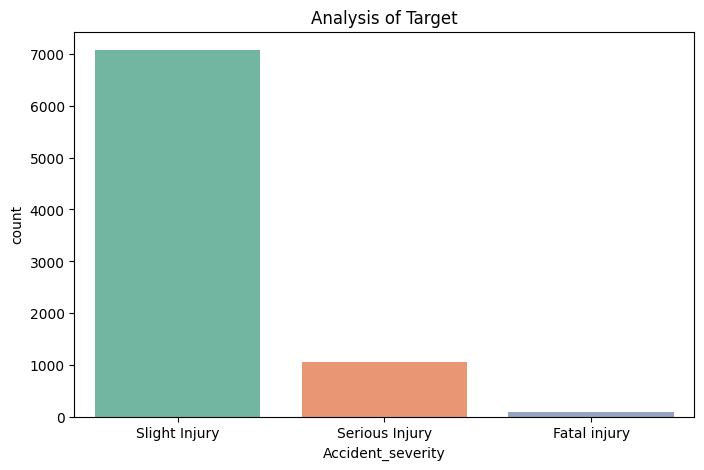

In [14]:
plt.figure(figsize=(8,5))
sns.countplot(
    data = data_df,
    x = "Accident_severity",
    palette = "Set2"
    )
plt.title("Analysis of Target")

The count plot shows the distribution of accident severity across three categories: Slight Injury, Serious Injury, and Fatal Injury. Slight Injury has the highest number of records (7,082), followed by Serious Injury (1,046), while Fatal Injury has the lowest number (82).

### 2. Individual Analysis

In [15]:
data_df["Weather_conditions"].value_counts()

Weather_conditions
Normal               6782
Raining               778
Unknown               255
Other                 207
Cloudy                 65
Windy                  58
Snow                   33
Raining and Windy      26
Fog or mist             6
Name: count, dtype: int64

Text(0, 0.5, 'Number of Accidents')

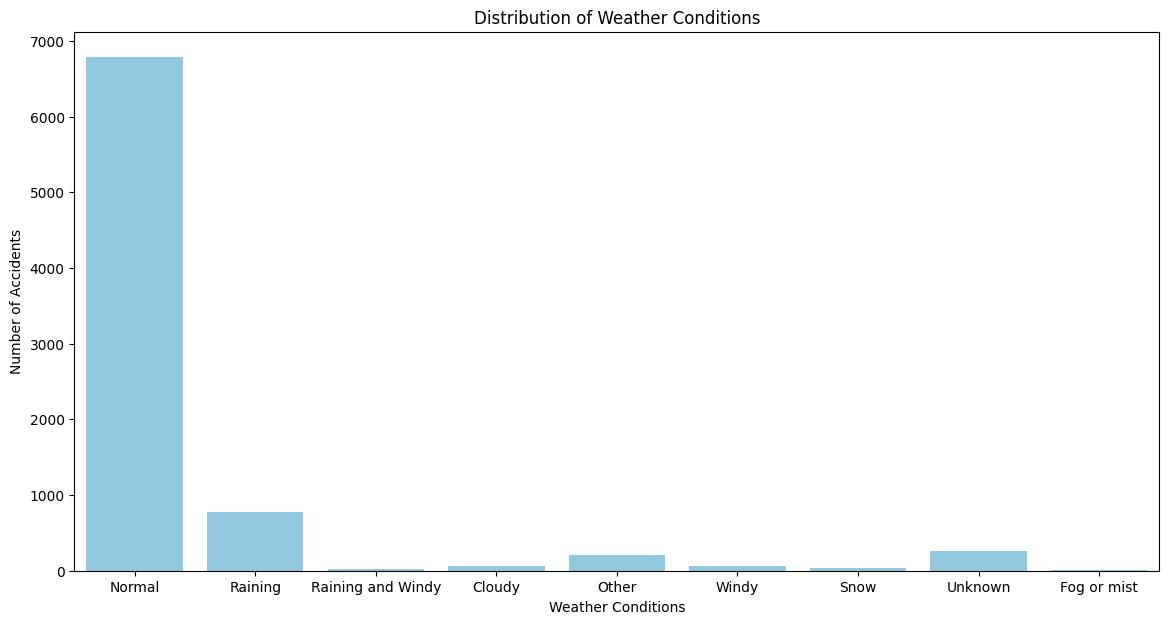

In [19]:
plt.figure(figsize=(14, 7))

sns.countplot(
    data=data_df,
    x="Weather_conditions",
    color="skyblue",
)

plt.title("Distribution of Weather Conditions")
plt.xlabel("Weather Conditions")
plt.ylabel("Number of Accidents")

The count plot shows the distribution of weather conditions recorded during road traffic accidents. Most accident records occurred under normal weather conditions, followed by rainy weather. Other conditions, such as snow, fog, and windy weather, have relatively fewer records.

This analysis shows the frequency of accidents across different weather conditions but does not establish whether weather conditions are associated with accident severity.

In [22]:
weather_severity = pd.crosstab(
    data_df["Weather_conditions"],
    data_df["Accident_severity"],
) 

In [23]:
weather_severity

Accident_severity,Fatal injury,Serious Injury,Slight Injury
Weather_conditions,,,
Cloudy,0,4,61
Fog or mist,0,1,5
Normal,75,887,5820
Other,0,24,183
Raining,7,87,684
Raining and Windy,0,0,26
Snow,0,5,28
Unknown,0,29,226
Windy,0,9,49


### 3. Light condition analysis

In [25]:
data_df["Light_conditions"].value_counts()

Light_conditions
Daylight                   5924
Darkness - lights lit      2171
Darkness - no lighting      100
Darkness - lights unlit      15
Name: count, dtype: int64

Text(0, 0.5, 'Number of Accidents')

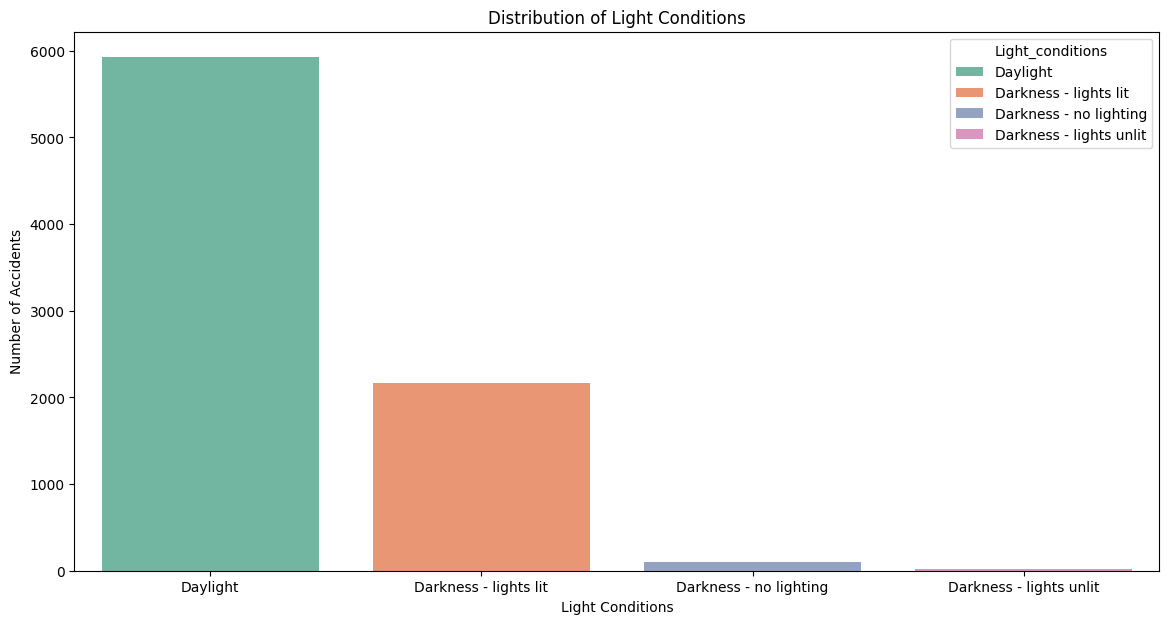

In [31]:
plt.figure(figsize=(14, 7))

sns.countplot(
    data=data_df,
    x="Light_conditions",
    hue="Light_conditions",
    palette="Set2",
     legend=True
)

plt.title("Distribution of Light Conditions")
plt.xlabel("Light Conditions")
plt.ylabel("Number of Accidents")

In [28]:
light_severity = pd.crosstab(
    data_df["Light_conditions"],
    data_df["Accident_severity"],
    normalize="index"
) * 100

light_severity.round(2)

Accident_severity,Fatal injury,Serious Injury,Slight Injury
Light_conditions,,,
Darkness - lights lit,1.52,12.90,85.58
Darkness - lights unlit,0.00,26.67,73.33
Darkness - no lighting,5.00,22.00,73.00
Daylight,0.74,12.49,86.77


This shows that daylight is the most frequently recorded lighting condition in the dataset. However, it does not necessarily mean that daylight is more dangerous, as the number of vehicles travelling under each lighting condition is unknown.

### 4. Road surface condition

In [32]:
data_df["Road_surface_conditions"].value_counts()

Road_surface_conditions
Dry                     6515
Wet or damp             1660
Snow                      33
Flood over 3cm. deep       2
Name: count, dtype: int64

Text(0, 0.5, 'Number of Accidents')

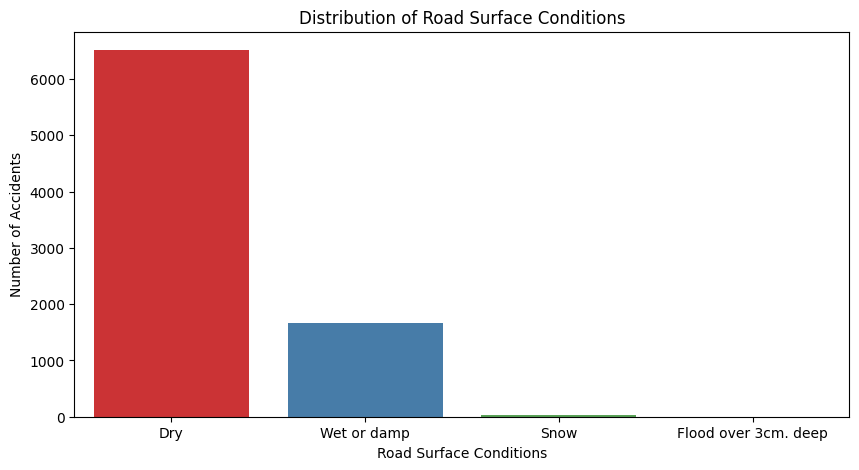

In [35]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=data_df,
    x="Road_surface_conditions",
    hue="Road_surface_conditions",
    palette="Set1",
    legend=False
)

plt.title("Distribution of Road Surface Conditions")
plt.xlabel("Road Surface Conditions")
plt.ylabel("Number of Accidents")

This indicates that dry road surfaces are the most frequently recorded condition in the dataset. However, it does not necessarily mean dry roads are more dangerous, as the amount of traffic under each road condition is unknown. 

### 5. Number of casulaties analysis

In [40]:
data_df["Number_of_casualties"].value_counts()

Number_of_casualties
1    5786
2    1440
3     531
4     256
5     131
6      51
8       8
7       7
Name: count, dtype: int64

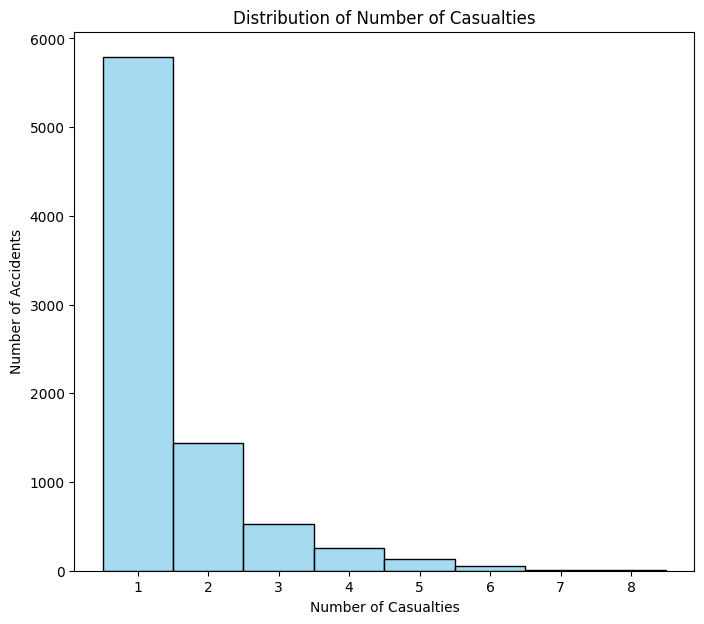

In [43]:
plt.figure(figsize=(8, 7))

sns.histplot(
    data=data_df,
    x="Number_of_casualties",
    discrete=True,
    color="skyblue",
)

plt.title("Distribution of Number of Casualties")
plt.xlabel("Number of Casualties")
plt.ylabel("Number of Accidents")
plt.show()

The highest bar represents approximately 5,800 separate accidents, where exactly one person was injured or killed in each accident. Around 1,450 accidents involved two casualties each, meaning two people were injured or killed in each of those accidents. As the number of casualties increases from 3 to 8, the number of recorded accidents gradually decreases.

The histogram is right-skewed (positively skewed), showing that accidents involving one or two casualties are much more common than accidents involving larger numbers of casualties.

### 7. Vehicle involved and number of casualties analysis

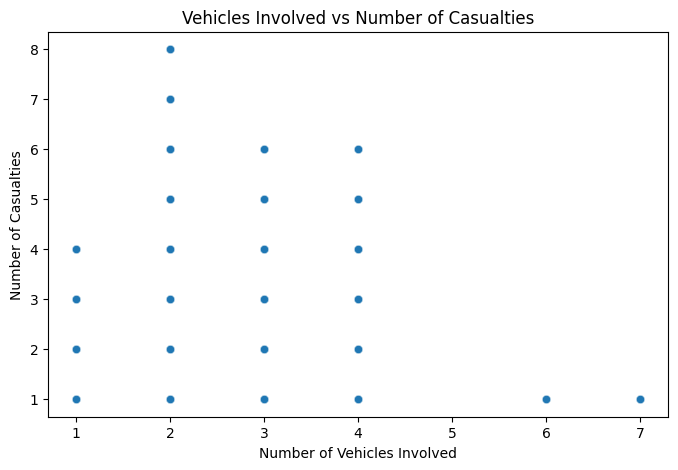

In [47]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=data_df,
    x="Number_of_vehicles_involved",
    y="Number_of_casualties",
    alpha=0.5
)

plt.title("Vehicles Involved vs Number of Casualties")
plt.xlabel("Number of Vehicles Involved")
plt.ylabel("Number of Casualties")
plt.show()

The graph shows that accidents involving two vehicles can have as many as eight casualties, while some accidents involving six or seven vehicles have only one casualty. This indicates that a higher number of vehicles involved does not always correspond to a higher number of casualties.

### 8. Correlation Analysis of Numerical Features

In [48]:
numerical_cols = data_df.select_dtypes(include="number")

In [54]:
numerical_cols = numerical_cols.drop(columns=["Num"])

In [57]:
correlation= numerical_cols.corr()

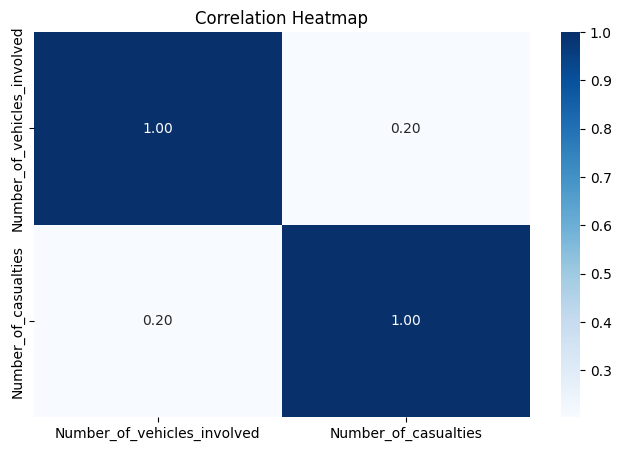

In [60]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    data = correlation,
    annot=True,
    cmap="Blues",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

The correlation coefficient between these two features is 0.20, indicating a weak positive linear relationship. This suggests that accidents involving more vehicles tend to have slightly higher casualty counts, but the relationship is not strong.

The diagonal values are 1.00 because each numerical feature is perfectly correlated with itself.

Overall, the number of vehicles involved alone does not strongly explain the variation in the number of casualties.